# HOMEWORK 12

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW12

In this homework, you are going to use the code from ```TrafficSignsClassification``` notebook and create your own traffic sign classifier.

In [1]:
# Silent installation or update

import sys
from packaging.requirements import Requirement
from importlib.metadata import PackageNotFoundError, version

# Clean cache
!"{sys.executable}" -m pip cache purge -q

# Force updating
package_update = [
    "pip",
    "scikit-learn",
    "pandas",
]

for package_name in package_update:
    !"{sys.executable}" -m pip install -U "{package_name}" -q

# Install missing packages
package_array = [
    "jinja2",
    "ipywidgets",
    "nbformat",
    "numpy",
    "matplotlib",
    "opencv-contrib-python",
    "torch",
    "keras",
]



def is_package_satisfied(req_str: str) -> bool:
    try:
        req = Requirement(req_str)
        installed_ver = version(req.name)
        if req.specifier:
            return installed_ver in req.specifier
        return True
    except PackageNotFoundError:
        return False


for package_name in package_array:
    if not is_package_satisfied(package_name):
        !"{sys.executable}" -m pip install "{package_name}" -q


In [2]:
# Synchronization with remote source

import shutil
from pathlib import Path

# Input images
hm_version = 12

# Solution
git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}.git"
main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"

# upload all files
current_path = !pwd
current_path = current_path[0]
parent_path = !dirname "$current_path"
parent_path = parent_path[0]
temp_path = f"{parent_path}/temp"

# Clone images
!rm -rf "$temp_path"
!git clone "$git_project_url" "$temp_path"

source = Path(temp_path)
destination = Path(current_path)
exclude = {main_file_name, ".git", ".idea"}

for item in source.iterdir():
    if item.name in exclude:
        continue

    target = destination / item.name
    if item.is_dir():
        shutil.copytree(item, target, dirs_exist_ok=True)
    else:
        shutil.copy2(item, target)

# Clean temp folder
!rm -rf "$temp_path"


### Step 1

Use the data from ```data/subset_homework.pckl``` (or the ```data/subset_homework``` folder) and visualize some examples. How many images are there for each class?

In [3]:
# Load data

import pickle
import numpy as np
from pathlib import Path
import apps.reporter as rpt

# Input data
n_images = 6
file_name = "resources/data/subset_homework.pckl"

# Solution
file_path = Path(file_name)

# Load data
if file_path.exists():
    with open(file_path, "rb") as f:
        data = pickle.load(f)
else:
    raise FileNotFoundError("File doesn't exist!")

if data is None:
    raise ValueError(f'Incorrect input data "{file_name}"!')

# form classes
class_id_0 = 0
class_id_1 = 1

# get data set
images_0 = data["class_id_0"]
images_1 = data["class_id_1"]

# get lengths
len_0 = len(images_0)
len_1 = len(images_1)

# form labels
labels_0 = np.full(len_0, class_id_0)
labels_1 = np.full(len_1, class_id_1)

# analysis image
temp_img = images_0[0]

# preparing set of images for showing
first_images = []
for idx in range(n_images):
    first_images.append((labels_0[idx], images_0[idx]))
    first_images.append((labels_1[idx], images_1[idx]))

rp = rpt.Reporter()
rp.add_item(f"Class {class_id_0} samples count", str(len_0))
rp.add_item(f"Class {class_id_1} samples count", str(len_1))
rp.add_item("Total dataset samples", str(len_0 + len_1))
rp.add_item("Image: (rows, cols, channels)", str(temp_img.shape))

# Print results
rp.print_pd_report("Dataset Summary")


Attribute,Result
Class 0 samples count,2220
Class 1 samples count,2250
Total dataset samples,4470
"Image: (rows, cols, channels)","(28, 28)"


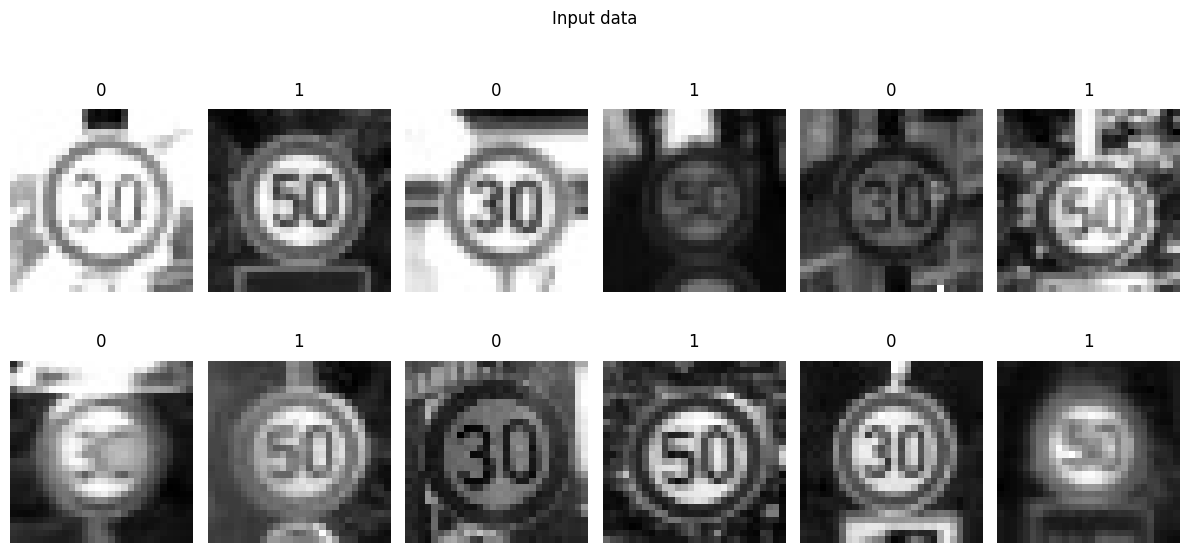

In [4]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = n_images
images_dict = first_images
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 3 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_dict):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_dict), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("Input data", y=1.0)
plt.tight_layout()
plt.show()


### Step 2

Run the training with one single neuron (as we did in the lecture). What accuracy can you achieve?

Model: "single_linear_neuron"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_pixels (InputLayer)       │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ single_neuron (Dense)           │ (None, 1)              │           785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 785 (3.07 KB)

 Trainable params: 785 (3.07 KB)

 Non-trainable params: 0 (0.00 B)

Total training:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1, Loss: 0.6330, Accuracy: 0.5711, Status: 10.00%
Epoch: 2, Loss: 0.3305, Accuracy: 0.6673, Status: 20.00%
Epoch: 3, Loss: 0.2216, Accuracy: 0.7568, Status: 30.00%
Epoch: 4, Loss: 0.1675, Accuracy: 0.8168, Status: 40.00%
Epoch: 5, Loss: 0.1436, Accuracy: 0.8481, Status: 50.00%
Epoch: 6, Loss: 0.1230, Accuracy: 0.8740, Status: 60.00%
Epoch: 7, Loss: 0.1180, Accuracy: 0.8855, Status: 70.00%
Epoch: 8, Loss: 0.1062, Accuracy: 0.8964, Status: 80.00%
Epoch: 9, Loss: 0.0970, Accuracy: 0.9114, Status: 90.00%
Epoch: 10, Loss: 0.0916, Accuracy: 0.9201, Status: 100.00%


Attribute,Result
Model Architecture,Single Dense Neuron (Linear)
Loss Function,Mean Squared Error (MSE)
Optimizer,Adam
Learning Rate,0.0010
Batch Size,32
Epochs,10
Initial Bias,0.0000
Trained Bias,0.5010
Final Loss,0.0916
Achieved Accuracy,0.9201


Attribute,Result
Confusion Matrix,[[1972 248] [ 109 2141]]
Accuracy (Точність),0.9201
Precision (Влучність),0.8962
Recall (Повнота),0.9516
F1-score,0.9230
Receiver Operating Characteristic (ROC-AUC),0.9794
Average Precision (AP),0.9805


              precision    recall  f1-score   support

           0       0.95      0.89      0.92      2220
           1       0.90      0.95      0.92      2250

    accuracy                           0.92      4470
   macro avg       0.92      0.92      0.92      4470
weighted avg       0.92      0.92      0.92      4470



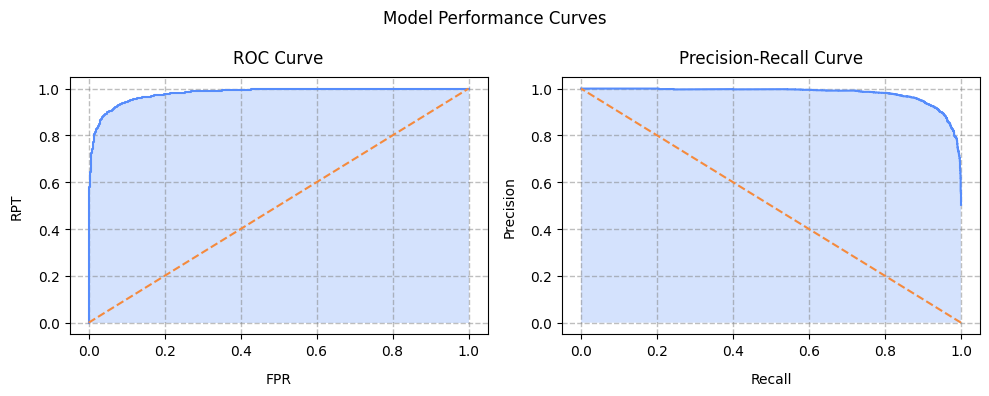

In [5]:
# Single Neuron Training

import numpy as np
import copy
import os

os.environ['KERAS_BACKEND'] = 'torch'

import keras
from keras import Model
from keras.layers import Dense, Input
from sklearn.utils import shuffle
from tqdm.auto import tqdm
from sklearn.preprocessing import StandardScaler
import apps.main as mn
import apps.reporter as rpt

# Input data
learning_rate = 0.001
n_epochs = 10
batch_size = 32
# to get similar results every time
rng_seed = 42

# Solution
# merging data
images_01 = np.concatenate([images_0, images_1])
labels_01 = np.concatenate([labels_0, labels_1])
# shuffle
images, labels = shuffle(images_01, labels_01, random_state=rng_seed)
images_flat = np.array(images, dtype=np.float32).reshape(len(images), -1)

# scaling
# (used from https://github.com/BogdanPinchuk/DataScience-PBY_HW18)
scaler = StandardScaler()
pixels = scaler.fit_transform(images_flat)
# for testing/comparing
# pixels = images_flat / 255.0

# set similar behavior for keras
keras.utils.set_random_seed(rng_seed)

# preparing model
inputs = Input(shape=(pixels.shape[1],), name="input_pixels")
outputs = Dense(1, activation="linear", kernel_initializer="glorot_uniform", name="single_neuron")(inputs)
model_single = Model(inputs=inputs, outputs=outputs, name="single_linear_neuron")
# print model
model_single.summary()

# extract init weights
weights_init, bias_init = copy.deepcopy(model_single.layers[1].get_weights())

# compiling
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
# for testing/comparing
# optimizer = keras.optimizers.SGD(learning_rate=learning_rate)
model_single.compile(optimizer=optimizer, loss="mean_squared_error", metrics=["accuracy"])

# training
# for testing/comparing
# history_single = model_single.fit(pixels, labels, epochs=n_epochs, batch_size=batch_size, verbose=2)

losses_single = []
accuracies_single = []

# (used from https://github.com/BogdanPinchuk/DataScience-PBY_HW22)
history_single = None
total_pbar = tqdm(range(n_epochs), desc="Total training", leave=True)
for epoch in total_pbar:
    history_single = model_single.fit(pixels, labels, epochs=1, batch_size=batch_size, verbose=0)
    avg_loss = history_single.history['loss'][-1]
    losses_single.append(avg_loss)
    avg_acc = history_single.history['accuracy'][-1]
    accuracies_single.append(avg_acc)
    # print data in console
    total_pbar.write(
        f"Epoch: {epoch + 1}, Loss: {avg_loss:.4f}, Accuracy: {avg_acc:.4f}, Status: {(epoch + 1.0) / n_epochs:.2%}")

labels_prob = model_single.predict(pixels, verbose=0).squeeze()
labels_pred = (labels_prob >= 0.5).astype(float)

# trained weights
weights_trained, bias_trained = model_single.layers[1].get_weights()
weight_diff = weights_trained - weights_init

images_single = {
    "Initial weights": weights_init.copy().reshape(temp_img.shape),
    "Trained weights": weights_trained.copy().reshape(temp_img.shape),
    "Weight Delta (Trained - Initial)": weight_diff.copy().reshape(temp_img.shape),
}

rp = rpt.Reporter()
rp.tolerance = 4
rp.add_item("Model Architecture", "Single Dense Neuron (Linear)")
rp.add_item("Loss Function", "Mean Squared Error (MSE)")
rp.add_item("Optimizer", "Adam")
rp.add_item("Learning Rate", rp.format_value(learning_rate))
rp.add_item("Batch Size", str(batch_size))
rp.add_item("Epochs", str(n_epochs))
rp.add_item("Initial Bias", rp.format_value(float(bias_init[0])))
rp.add_item("Trained Bias", rp.format_value(float(bias_trained[0])))
rp.add_item("Final Loss", rp.format_value(losses_single[-1]))
rp.add_item("Achieved Accuracy", rp.format_value(accuracies_single[-1]))

# Print results
rp.print_pd_report("Single Neuron Baseline Performance")
df_metrics_single = mn.calc_class_metrics(labels, labels_pred, labels_prob)


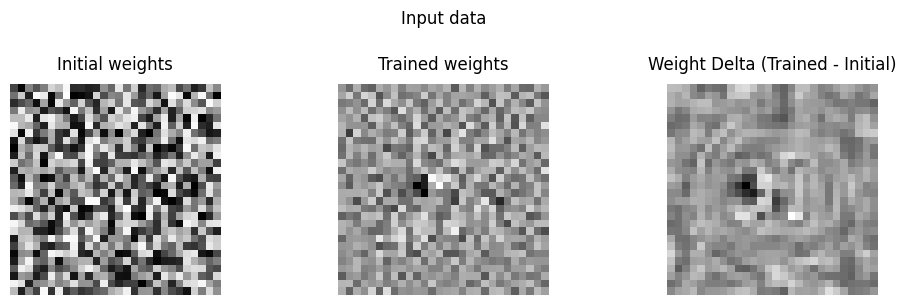

In [6]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 3
images_dict = images_single
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(10, 3 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_dict.items()):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_dict), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("Input data", y=1.0)
plt.tight_layout()
plt.show()


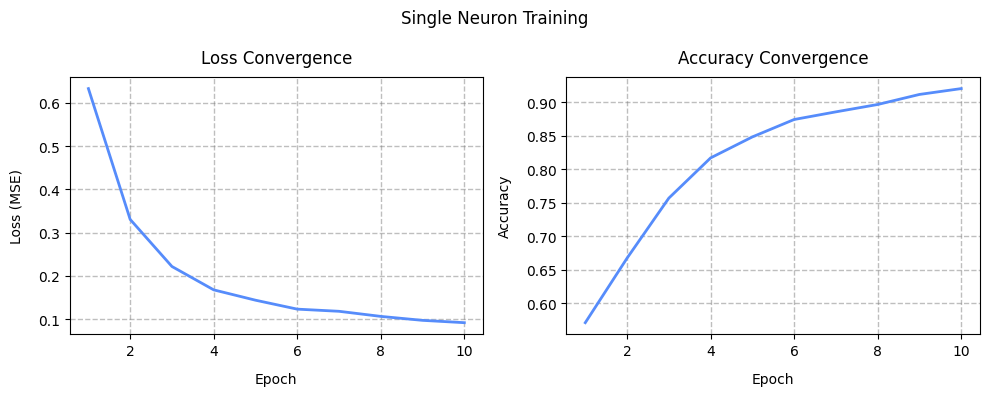

In [7]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
array_x = range(1, n_epochs + 1)
array_y0 = losses_single
array_y1 = accuracies_single

# Solution
_, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.plot(array_x, array_y0, linewidth=2.0)
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Loss Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epoch", labelpad=10, loc='center', color='black')
ax.set_ylabel("Loss (MSE)", labelpad=10, loc='center', color='black')

ax = axes[1]
ax.plot(array_x, array_y1, linewidth=2.0)
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Accuracy Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epoch", labelpad=10, loc='center', color='black')
ax.set_ylabel("Accuracy", labelpad=10, loc='center', color='black')

plt.suptitle(f"Single Neuron Training")

plt.tight_layout()
plt.show()

### Step 3

Make further modifications to improve the accuracy (e.g. add more neurons, more layers, etc.). What is the maximum accuracy you can achieve?

*Note: the accuracy you compute here is measured on the same images the model was trained on. We will discuss how to evaluate a model properly in one of the next lessons.*

Model: "modified_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_pixels (InputLayer)       │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_1 (Dense)          │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_classification (Dense)   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,297 (200.38 KB)

 Trainable params: 51,297 (200.38 KB)

 Non-trainable params: 0 (0.00 B)

Total training:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1, Loss: 0.4802, Accuracy: 0.7763, Status: 10.00%
Epoch: 2, Loss: 0.2120, Accuracy: 0.9300, Status: 20.00%
Epoch: 3, Loss: 0.1644, Accuracy: 0.9409, Status: 30.00%
Epoch: 4, Loss: 0.1261, Accuracy: 0.9523, Status: 40.00%
Epoch: 5, Loss: 0.1211, Accuracy: 0.9559, Status: 50.00%
Epoch: 6, Loss: 0.0834, Accuracy: 0.9720, Status: 60.00%
Epoch: 7, Loss: 0.0920, Accuracy: 0.9651, Status: 70.00%
Epoch: 8, Loss: 0.0799, Accuracy: 0.9709, Status: 80.00%
Epoch: 9, Loss: 0.0719, Accuracy: 0.9720, Status: 90.00%
Epoch: 10, Loss: 0.0500, Accuracy: 0.9817, Status: 100.00%


Attribute,Result
Model Architecture,Deep MLP (64 LeakyReLU -> 16 ELU -> 1 Sigmoid)
Trainable Parameters,"51,297"
Loss Function,Binary Cross-Entropy (BCE)
Optimizer,Adam
Learning Rate,0.0010
Batch Size,32
Epochs,10
Initial Loss,0.4802
Final Loss,0.0500
Achieved Accuracy,0.9817


Attribute,Result
Confusion Matrix,[[2199 21] [ 12 2238]]
Accuracy (Точність),0.9926
Precision (Влучність),0.9907
Recall (Повнота),0.9947
F1-score,0.9927
Receiver Operating Characteristic (ROC-AUC),0.9994
Average Precision (AP),0.9994


              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2220
           1       0.99      0.99      0.99      2250

    accuracy                           0.99      4470
   macro avg       0.99      0.99      0.99      4470
weighted avg       0.99      0.99      0.99      4470



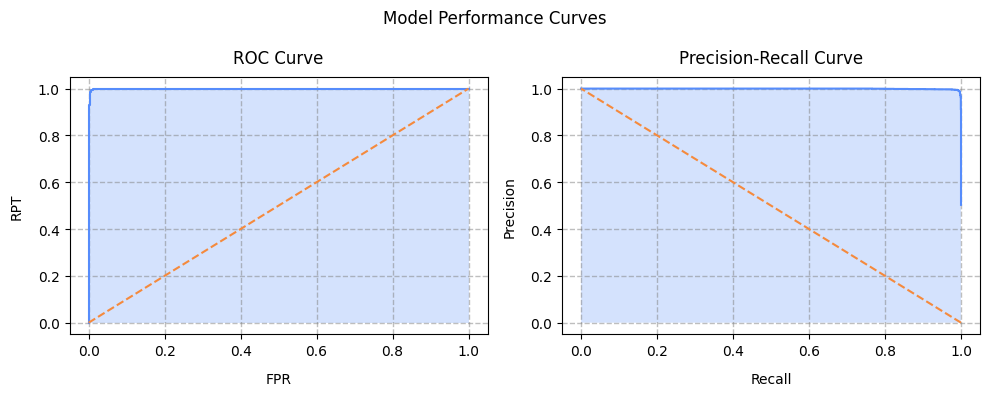

In [8]:
# Multi-Layer Perceptron

import os

os.environ['KERAS_BACKEND'] = 'torch'

import keras
from keras import Model
from keras.layers import Dense, Input
from tqdm.auto import tqdm
import apps.main as mn
import apps.reporter as rpt

# Input data
learning_rate = 0.001
n_epochs = 10
batch_size = 32
# to get similar results every time
rng_seed = 42

# Solution
# set similar behavior for keras
keras.utils.set_random_seed(rng_seed)


# preparing model
def build_model():
    inputs = Input(shape=(pixels.shape[1],), name="input_pixels")
    net = Dense(64, activation="leaky_relu", kernel_initializer="he_normal", name="hidden_layer_1")(inputs)
    net = Dense(16, activation="elu", kernel_initializer="he_normal", name="hidden_layer_2")(net)
    outputs = Dense(1, activation="sigmoid", kernel_initializer="glorot_uniform", name="output_classification")(net)
    return Model(inputs=inputs, outputs=outputs, name="modified_model")


modified_model = build_model()
# print model
modified_model.summary()

# compiling
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
# for testing/comparing
# optimizer = keras.optimizers.SGD(learning_rate=learning_rate)
modified_model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=["accuracy"])

# training
# for testing/comparing
# history_mlp = modified_model.fit(pixels, labels, epochs=n_epochs, batch_size=batch_size, verbose=2)

losses_mlp = []
accuracies_mlp = []

# (used from https://github.com/BogdanPinchuk/DataScience-PBY_HW22)
history_mlp = None
total_pbar = tqdm(range(n_epochs), desc="Total training", leave=True)
for epoch in total_pbar:
    history_mlp = modified_model.fit(pixels, labels, epochs=1, batch_size=batch_size, verbose=0)
    avg_loss = history_mlp.history['loss'][-1]
    losses_mlp.append(avg_loss)
    avg_acc = history_mlp.history['accuracy'][-1]
    accuracies_mlp.append(avg_acc)
    # print data in console
    total_pbar.write(
        f"Epoch: {epoch + 1}, Loss: {avg_loss:.4f}, Accuracy: {avg_acc:.4f}, Status: {(epoch + 1.0) / n_epochs:.2%}")

labels_prob = modified_model.predict(pixels, verbose=0).squeeze()
labels_pred = (labels_prob >= 0.5).astype(float)

rp = rpt.Reporter()
rp.tolerance = 4
rp.add_item("Model Architecture", "Deep MLP (64 LeakyReLU -> 16 ELU -> 1 Sigmoid)")
rp.add_item("Trainable Parameters", f"{modified_model.count_params():,}")
rp.add_item("Loss Function", "Binary Cross-Entropy (BCE)")
rp.add_item("Optimizer", "Adam")
rp.add_item("Learning Rate", rp.format_value(learning_rate))
rp.add_item("Batch Size", str(batch_size))
rp.add_item("Epochs", str(n_epochs))
rp.add_item("Initial Loss", rp.format_value(losses_mlp[0]))
rp.add_item("Final Loss", rp.format_value(losses_mlp[-1]))
rp.add_item("Achieved Accuracy", rp.format_value(accuracies_mlp[-1]))

# Print results
rp.print_pd_report("Multi-Layer Perceptron Performance")
df_metrics_mlp = mn.calc_class_metrics(labels, labels_pred, labels_prob)


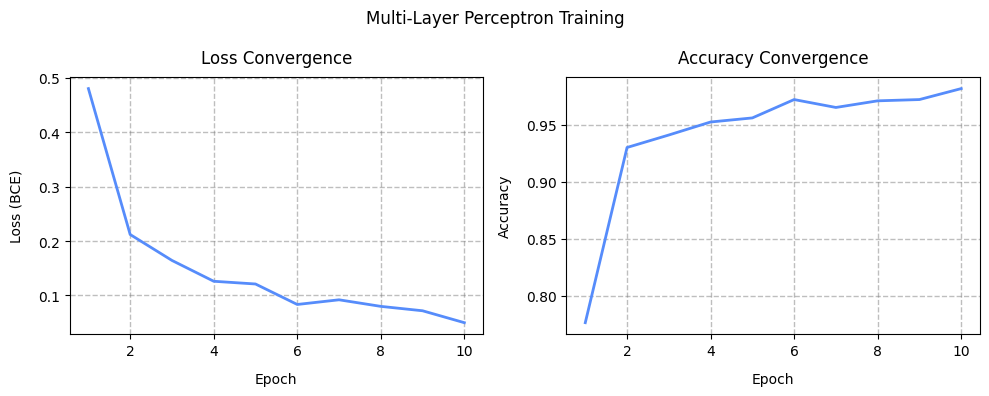

In [9]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
array_x = range(1, n_epochs + 1)
array_y0 = losses_mlp
array_y1 = accuracies_mlp

# Solution
_, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.plot(array_x, array_y0, linewidth=2.0)
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Loss Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epoch", labelpad=10, loc='center', color='black')
ax.set_ylabel("Loss (BCE)", labelpad=10, loc='center', color='black')

ax = axes[1]
ax.plot(array_x, array_y1, linewidth=2.0)
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Accuracy Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epoch", labelpad=10, loc='center', color='black')
ax.set_ylabel("Accuracy", labelpad=10, loc='center', color='black')

plt.suptitle(f"Multi-Layer Perceptron Training")

plt.tight_layout()
plt.show()

In [10]:
# Comparing models

from apps.reporter import Reporter

# Input data
models_comparison = [
    ("Baseline (Single Linear Neuron)", df_metrics_single),
    ("Deep MLP (64 LeakyReLU -> 16 ELU -> 1 Sigmoid)", df_metrics_mlp),
]

# Solution

# Print results
Reporter.print_concat_pd_reports(models_comparison, "Comparative Classification Performance (Baseline vs MLP)")

,Confusion Matrix,Accuracy (Точність),Precision (Влучність),Recall (Повнота),F1-score,Receiver Operating Characteristic (ROC-AUC),Average Precision (AP)
Baseline (Single Linear Neuron),[[1972 248] [ 109 2141]],0.9201,0.8962,0.9516,0.9230,0.9794,0.9805
Deep MLP (64 LeakyReLU -> 16 ELU -> 1 Sigmoid),[[2199 21] [ 12 2238]],0.9926,0.9907,0.9947,0.9927,0.9994,0.9994


### Bonus question

Stack two ```Dense``` layers with ```activation="linear"``` on top of each other. Do you get a better model than with one single neuron? Why (not)? Hint: have a look at the slide about the neural network and non-linearity.

Model: "stacked_linear_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_pixels (InputLayer)       │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ linear_layer_1 (Dense)          │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ linear_layer_2 (Dense)          │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,305 (196.50 KB)

 Trainable params: 50,305 (196.50 KB)

 Non-trainable params: 0 (0.00 B)

Total training:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1, Loss: 0.5321, Accuracy: 0.7022, Status: 10.00%
Epoch: 2, Loss: 0.1838, Accuracy: 0.8295, Status: 20.00%
Epoch: 3, Loss: 0.2493, Accuracy: 0.7960, Status: 30.00%
Epoch: 4, Loss: 0.1181, Accuracy: 0.8877, Status: 40.00%
Epoch: 5, Loss: 0.1276, Accuracy: 0.8734, Status: 50.00%
Epoch: 6, Loss: 0.0972, Accuracy: 0.9116, Status: 60.00%
Epoch: 7, Loss: 0.1352, Accuracy: 0.8613, Status: 70.00%
Epoch: 8, Loss: 0.1171, Accuracy: 0.8837, Status: 80.00%
Epoch: 9, Loss: 0.1250, Accuracy: 0.8749, Status: 90.00%
Epoch: 10, Loss: 0.1089, Accuracy: 0.8962, Status: 100.00%


Attribute,Result
Model Architecture,Stacked Linear Layers (64 Linear -> 1 Linear)
Loss Function,Mean Squared Error (MSE)
Optimizer,Adam
Learning Rate,0.0010
Batch Size,32
Epochs,10
Initial Loss,0.5321
Final Loss,0.1089
Achieved Accuracy,0.8962


Attribute,Result
Confusion Matrix,[[1919 301] [ 114 2136]]
Accuracy (Точність),0.9072
Precision (Влучність),0.8765
Recall (Повнота),0.9493
F1-score,0.9115
Receiver Operating Characteristic (ROC-AUC),0.9770
Average Precision (AP),0.9792


              precision    recall  f1-score   support

           0       0.94      0.86      0.90      2220
           1       0.88      0.95      0.91      2250

    accuracy                           0.91      4470
   macro avg       0.91      0.91      0.91      4470
weighted avg       0.91      0.91      0.91      4470



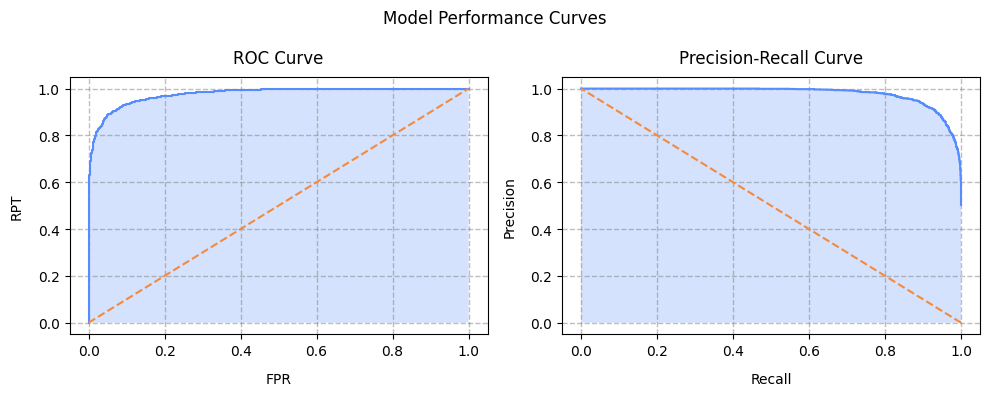

In [11]:
# Stacked Linear Layers (Bonus Experiment)

import os

os.environ['KERAS_BACKEND'] = 'torch'

import keras
from keras import Model
from keras.layers import Dense, Input
from tqdm.auto import tqdm
import apps.main as mn
import apps.reporter as rpt

# Input data
learning_rate = 0.001
n_epochs = 10
batch_size = 32
# to get similar results every time
rng_seed = 42

# Solution
# set similar behavior for keras
keras.utils.set_random_seed(rng_seed)

# preparing model
def build_linear_stacked_model():
    inputs = Input(shape=(pixels.shape[1],), name="input_pixels")
    net = Dense(64, activation="linear", kernel_initializer="glorot_uniform", name="linear_layer_1")(inputs)
    outputs = Dense(1, activation="linear", kernel_initializer="glorot_uniform", name="linear_layer_2")(net)
    return Model(inputs=inputs, outputs=outputs, name="stacked_linear_model")

model_linear_stacked = build_linear_stacked_model()
# print model
model_linear_stacked.summary()

# compiling
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
# for testing/comparing
# optimizer = keras.optimizers.SGD(learning_rate=learning_rate)
model_linear_stacked.compile(optimizer=optimizer, loss="mean_squared_error", metrics=["accuracy"])

# training
# for testing/comparing
# history_stacked = model_linear_stacked.fit(pixels, labels, epochs=n_epochs, batch_size=batch_size, verbose=2)

losses_stacked = []
accuracies_stacked = []

# (used from https://github.com/BogdanPinchuk/DataScience-PBY_HW22)
history_stacked = None
total_pbar = tqdm(range(n_epochs), desc="Total training", leave=True)
for epoch in total_pbar:
    history_stacked = model_linear_stacked.fit(pixels, labels, epochs=1, batch_size=batch_size, verbose=0)
    avg_loss = history_stacked.history['loss'][-1]
    losses_stacked.append(avg_loss)
    avg_acc = history_stacked.history['accuracy'][-1]
    accuracies_stacked.append(avg_acc)
    # print data in console
    total_pbar.write(
        f"Epoch: {epoch + 1}, Loss: {avg_loss:.4f}, Accuracy: {avg_acc:.4f}, Status: {(epoch + 1.0) / n_epochs:.2%}")

labels_prob = model_linear_stacked.predict(pixels, verbose=0).squeeze()
labels_pred = (labels_prob >= 0.5).astype(float)

rp = rpt.Reporter()
rp.tolerance = 4
rp.add_item("Model Architecture", "Stacked Linear Layers (64 Linear -> 1 Linear)")
rp.add_item("Loss Function", "Mean Squared Error (MSE)")
rp.add_item("Optimizer", "Adam")
rp.add_item("Learning Rate", rp.format_value(learning_rate))
rp.add_item("Batch Size", str(batch_size))
rp.add_item("Epochs", str(n_epochs))
rp.add_item("Initial Loss", rp.format_value(losses_stacked[0]))
rp.add_item("Final Loss", rp.format_value(losses_stacked[-1]))
rp.add_item("Achieved Accuracy", rp.format_value(accuracies_stacked[-1]))

# Print results
rp.print_pd_report("Stacked Linear Layers Performance")
df_metrics_stacked = mn.calc_class_metrics(labels, labels_pred, labels_prob)


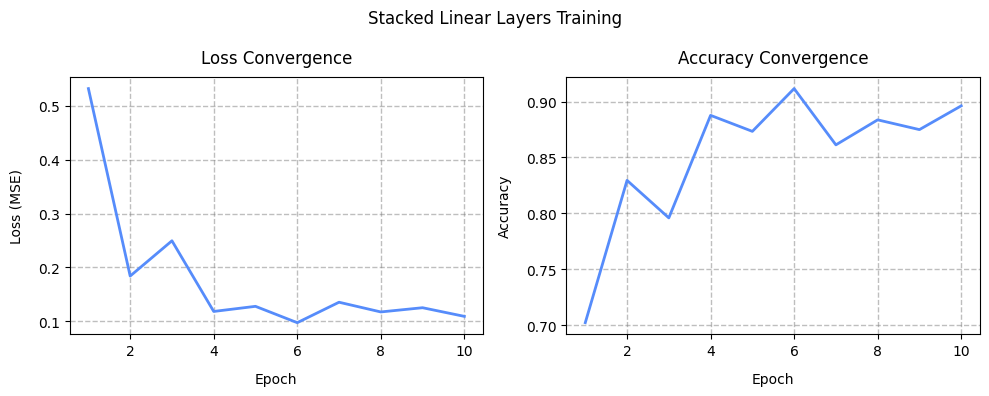

In [12]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
array_x = range(1, n_epochs + 1)
array_y0 = losses_stacked
array_y1 = accuracies_stacked

# Solution
_, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.plot(array_x, array_y0, linewidth=2.0)
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Loss Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epoch", labelpad=10, loc='center', color='black')
ax.set_ylabel("Loss (MSE)", labelpad=10, loc='center', color='black')

ax = axes[1]
ax.plot(array_x, array_y1, linewidth=2.0)
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Accuracy Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epoch", labelpad=10, loc='center', color='black')
ax.set_ylabel("Accuracy", labelpad=10, loc='center', color='black')

plt.suptitle(f"Stacked Linear Layers Training")

plt.tight_layout()
plt.show()

In [14]:
# Comparing models

from apps.reporter import Reporter

# Input data
models_comparison = [
    ("Baseline (Single Linear Neuron)", df_metrics_single),
    ("Stacked Linear Layers (64 Lin -> 1 Lin)", df_metrics_stacked),
    ("Deep MLP (64 LeakyReLU -> 16 ELU -> 1 Sigmoid)", df_metrics_mlp),
]

# Solution

# Print results
Reporter.print_concat_pd_reports(models_comparison, "Linear Collapse Verification & Architectural Benchmark")

,Confusion Matrix,Accuracy (Точність),Precision (Влучність),Recall (Повнота),F1-score,Receiver Operating Characteristic (ROC-AUC),Average Precision (AP)
Baseline (Single Linear Neuron),[[1972 248] [ 109 2141]],0.9201,0.8962,0.9516,0.9230,0.9794,0.9805
Stacked Linear Layers (64 Lin -> 1 Lin),[[1919 301] [ 114 2136]],0.9072,0.8765,0.9493,0.9115,0.9770,0.9792
Deep MLP (64 LeakyReLU -> 16 ELU -> 1 Sigmoid),[[2199 21] [ 12 2238]],0.9926,0.9907,0.9947,0.9927,0.9994,0.9994


### Conclusion
1. **Dataset Balance (Step 1):**
   - The dataset contains 4,470 grayscale images ($28 \times 28$ pixels), evenly distributed between the two traffic sign classes: **2,220** samples for Class 0 and **2,250** samples for Class 1.
2. **Single Neuron Baseline (Step 2):**
   - A single linear neuron trained with MSE loss achieved **92.01%** accuracy with **357 misclassified samples** (248 false positives, 109 false negatives). It acts as a linear hyperplane separator.
3. **Multi-Layer Perceptron (Step 3):**
   - Introducing hidden layers with non-linear activations (`64 LeakyReLU -> 16 ELU -> 1 Sigmoid`) and Binary Cross-Entropy loss propelled accuracy to **99.26%**.
   - Total errors dropped from 357 to just **33 samples** (a > 90% reduction in misclassifications), proving the necessity of non-linear feature representations for traffic sign discrimination.
4. **The Non-Linearity Invariant (Bonus Question):**
   - Stacking two linear layers without activation functions yielded no capacity improvement (**90.72%** accuracy). Due to the linearity of matrix multiplication, arbitrary depths of linear layers collapse while simultaneously degrading optimization efficiency.